In [4]:

#  pandas ->  work with data tables.
import pandas as pd

#  numpy -> perform mathematical operations.
import numpy as np

#  matplotlib -> create graphs.
import matplotlib.pyplot as plt

#  seaborn -> create attractive graphs.
import seaborn as sns

# Import a tool to divide dataset into training and testing data.
from sklearn.model_selection import train_test_split

# Import a simple model to create a baseline.
from sklearn.dummy import DummyClassifier

# Import Logistic Regression, my first machine learning model.
from sklearn.linear_model import LogisticRegression

# Import tools to measure model performance.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Import a tool to evaluate the model using cross-validation.
from sklearn.model_selection import cross_val_score

# check that everything works.
print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

# Import a tool to download files from the internet.
import urllib.request

# Give the UCI dataset download address.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

# Download the dataset and save it on our computer.
urllib.request.urlretrieve(url, "banknote_data.txt")

# Give meaningful names to the dataset columns.
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# Read the dataset and convert it into a table.
df = pd.read_csv(
    "banknote_data.txt",
    header=None,
    names=column_names
)

# Display a success message.
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [8]:
#print first 5 rows
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [9]:
df

,variance,skewness,curtosis,entropy,class
0,3.62160,8.66610,-2.8073,-0.44699,0
1,4.54590,8.16740,-2.4586,-1.46210,0
2,3.86600,-2.63830,1.9242,0.10645,0
3,3.45660,9.52280,-4.0112,-3.59440,0
4,0.32924,-4.45520,4.5718,-0.98880,0
...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1


In [11]:
#Number of rows and columns.
print("Dataset shape:", df.shape)

# Total number of rows.
print("Total records:", df.shape[0])

# Total number of columns.
print("Total columns:", df.shape[1])


Dataset shape: (1372, 5)
Total records: 1372
Total columns: 5


In [19]:
#Check missing values
print(df.isnull().sum())

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


Conclusion: Our dataset does not contain missing values. Therefore, we don't need to fill or remove missing values.

In [18]:
# Count the number of records in each banknote category.
print(df["class"].value_counts())

# Display the category names and their meanings.
print("0 = Genuine banknote")
print("1 = Forged banknote")


class
0    762
1    610
Name: count, dtype: int64
0 = Genuine banknote
1 = Forged banknote


In [21]:
# Count duplicate rows in the dataset.
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 24


Duplicate records are repeated rows in a dataset. We need to identify them before training our model.

In [23]:

# Display basic statistical information about the dataset.
df.describe()


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [24]:

# Display all rows that have duplicates.
duplicates = df[df.duplicated(keep=False)]

# Display the duplicate records.
duplicates.sort_values(
    by=["variance", "skewness", "curtosis", "entropy"]
)


,variance,skewness,curtosis,entropy,class
227,-2.6479,10.1374,-1.3310,-5.4707,0
604,-2.6479,10.1374,-1.3310,-5.4707,0
727,-2.6479,10.1374,-1.3310,-5.4707,0
107,-1.8584,7.8860,-1.6643,-1.8384,0
195,-1.8584,7.8860,-1.6643,-1.8384,0
345,-1.8584,7.8860,-1.6643,-1.8384,0
219,-1.3000,10.2678,-2.9530,-5.8638,0
284,-1.3000,10.2678,-2.9530,-5.8638,0
427,-1.3000,10.2678,-2.9530,-5.8638,0
45,-0.7869,9.5663,-3.7867,-7.5034,0


In [27]:
duplicates.describe()

,variance,skewness,curtosis,entropy,class
count,35.000000,35.000000,35.000000,35.000000,35.0
mean,-0.290909,3.100549,0.279200,-2.651986,0.0
std,1.098247,5.975753,3.074868,2.609646,0.0
min,-2.647900,-4.455200,-3.786700,-7.503400,0.0
25%,-1.043450,-3.263300,-2.953000,-5.470700,0.0
50%,0.329200,0.709800,0.757200,-0.988800,0.0
75%,0.519500,9.220700,3.089500,-0.562100,0.0
max,0.929700,10.267800,4.642900,-0.295700,0.0


In [28]:

# Count the number of records in each class.
class_counts = df["class"].value_counts().sort_index()

# Display the class counts.
print(class_counts)

# Display the meaning of each class.
print("0 = Genuine banknotes")
print("1 = Forged banknotes")


class
0    762
1    610
Name: count, dtype: int64
0 = Genuine banknotes
1 = Forged banknotes


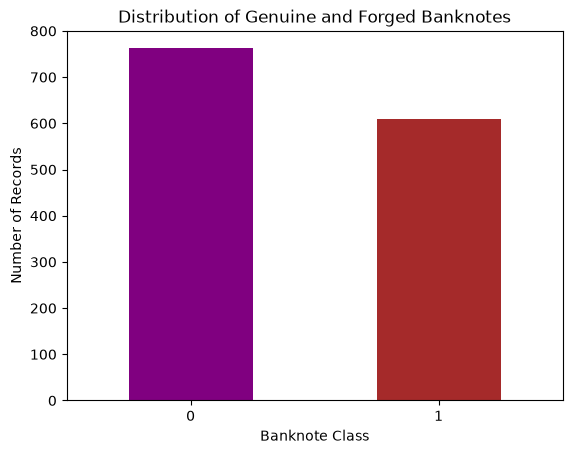

In [32]:

# Create a bar chart to show the number of banknotes in each class.
class_counts.plot(kind="bar", color=["purple", "brown"])

# Add a title to the graph.
plt.title("Distribution of Genuine and Forged Banknotes")

# Add a label to the horizontal axis.
plt.xlabel("Banknote Class")

# Add a label to the vertical axis.
plt.ylabel("Number of Records")

# Display the graph.
plt.xticks(rotation=0)
plt.show()
